*Author:*  
Manuel Eugenio Morocho Cayamcela, PhD

# Diabetes Prediction with a Keras Neural Network

Build, monitor, and evaluate a binary classifier using the Pima Indians diabetes dataset.

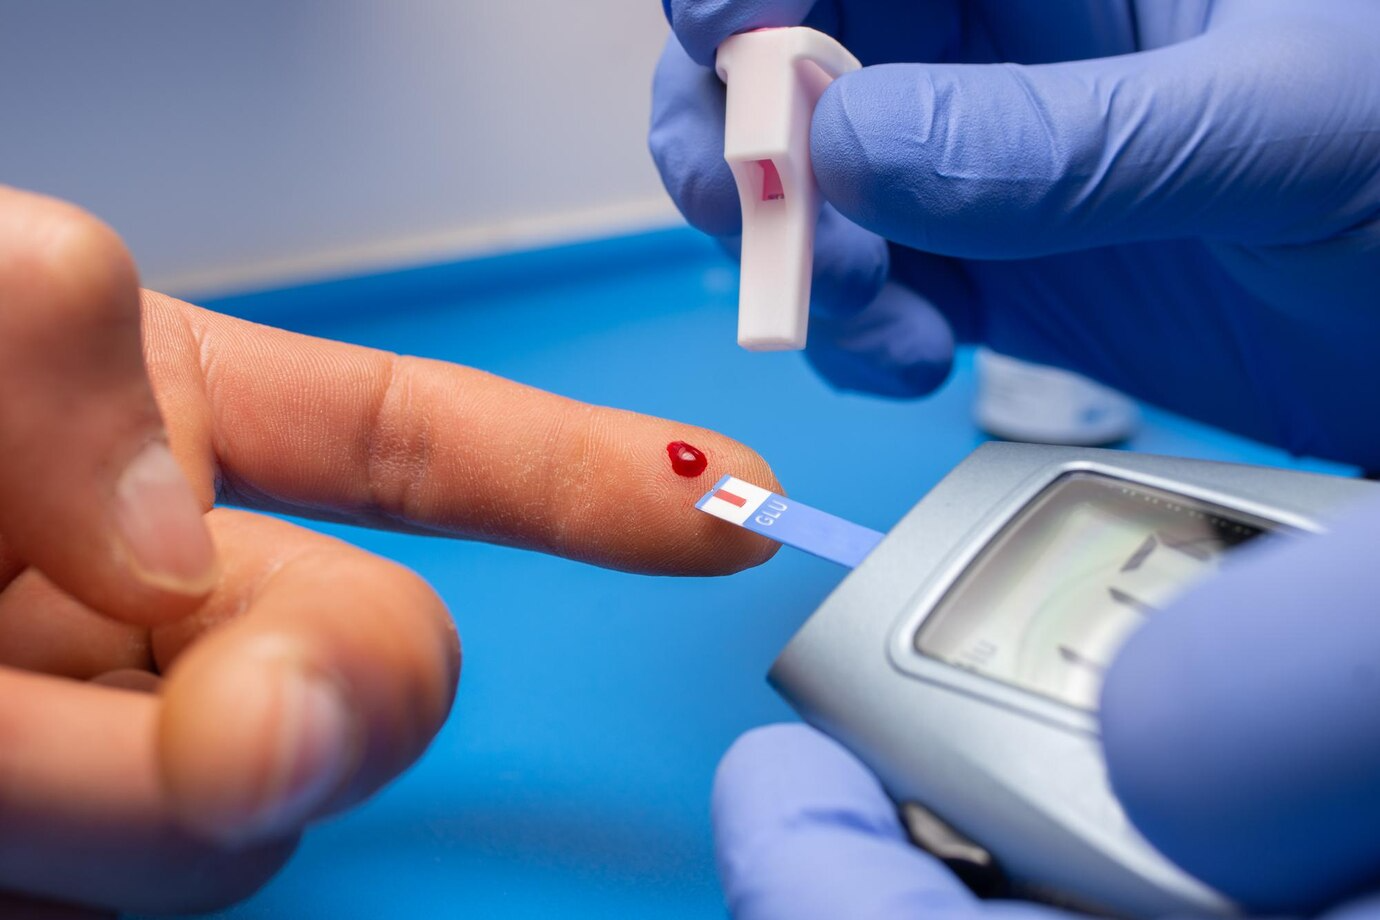

## Learning goals

- Prepare clinical features for modeling.
- Train a small Keras network for binary classification.
- Inspect learning curves with TensorBoard and use early stopping.

The target, `diabetes`, is `1` for diabetes and `0` otherwise.

python -c "import tensorflow as tf; print(tf.__version__)"## Contents

## 1. Load and inspect the data

Load `diabetes.csv` into a DataFrame and inspect the first rows. The dataset contains eight patient features and the binary `diabetes` target.

In [ ]:
%pip install -q pandas matplotlib seaborn scikit-learn tensorflow==2.19.0 tensorboard

Note: you may need to restart the kernel to use updated packages.


In [42]:
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import tensorflow as tf

#SEED = 42
#tf.keras.utils.set_random_seed(SEED)

In [43]:
diabetes_df = pd.read_csv(
    "https://raw.githubusercontent.com/eugeniomorocho/ArtificialIntelligence/81ef0be9d87c6ff996b0b391c89964f15a73f5be/datasets/diabetes.csv"
)
diabetes_df.head()

,pregnancies,glucose,diastolic,triceps,insulin,bmi,dpf,age,diabetes
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


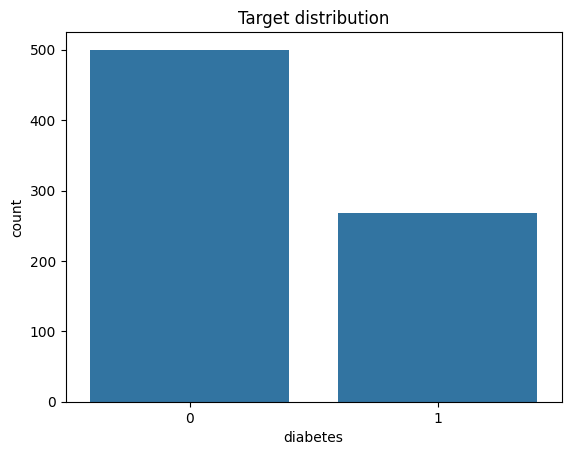

In [44]:
import seaborn as sns

sns.countplot(data=diabetes_df, x="diabetes")
plt.title("Target distribution");

**Features:** pregnancies, glucose, diastolic blood pressure, triceps skinfold thickness, insulin, BMI, diabetes pedigree function, and age.

Check the class balance before training.

## 2. Prepare the data

Inspect data types and missing values.

In [10]:
diabetes_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   pregnancies  768 non-null    int64  
 1   glucose      768 non-null    int64  
 2   diastolic    768 non-null    int64  
 3   triceps      768 non-null    int64  
 4   insulin      768 non-null    int64  
 5   bmi          768 non-null    float64
 6   dpf          768 non-null    float64
 7   age          768 non-null    int64  
 8   diabetes     768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


#### Outliers

##### Plot the value range of each column

A boxplot summarizes each feature's distribution through its median, quartiles, range, and potential outliers.

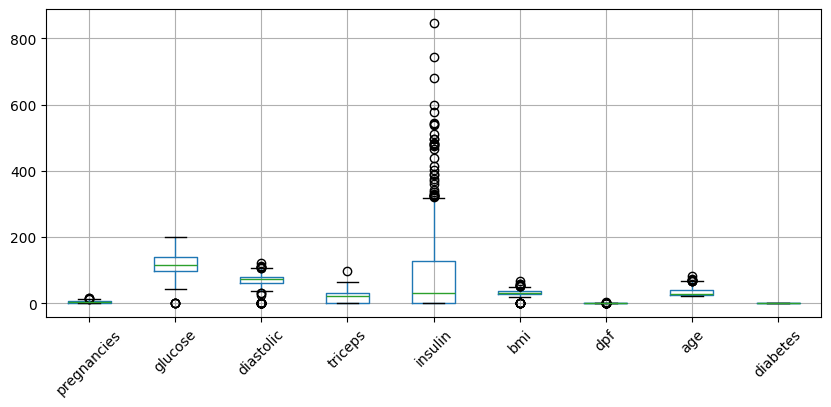

In [45]:
fig, ax = plt.subplots(figsize=(10, 4))
diabetes_df.boxplot(ax=ax)
plt.xticks(rotation=45)
plt.show()

Whether to remove outliers depends on the domain. In this dataset, extreme clinical values can be genuine, so we keep them for this example.

#### Replace zero values with NaN

For `glucose`, `diastolic`, `triceps`, `insulin`, and `bmi`, zero is physiologically implausible. Treat it as missing, then impute each feature with its mean.

We retain potential outliers for this introductory example.

In [46]:
import numpy as np

missing_value_columns = ["glucose", "diastolic", "triceps", "insulin", "bmi"]
diabetes_df[missing_value_columns] = diabetes_df[missing_value_columns].replace(0, np.nan)

#### Impute NaN values with the mean

Replace missing values in each numeric feature with that feature's mean.

In [47]:
diabetes_df = diabetes_df.fillna(diabetes_df.mean())
diabetes_df.head()

,pregnancies,glucose,diastolic,triceps,insulin,bmi,dpf,age,diabetes
0,6,148.0,72.0,35.00000,155.548223,33.6,0.627,50,1
1,1,85.0,66.0,29.00000,155.548223,26.6,0.351,31,0
2,8,183.0,64.0,29.15342,155.548223,23.3,0.672,32,1
3,1,89.0,66.0,23.00000,94.000000,28.1,0.167,21,0
4,0,137.0,40.0,35.00000,168.000000,43.1,2.288,33,1


#### Plot feature correlations

Use a correlation heatmap to identify linear relationships. Correlation is not causation; weak individual correlations can still be useful in combination.

<Axes: >

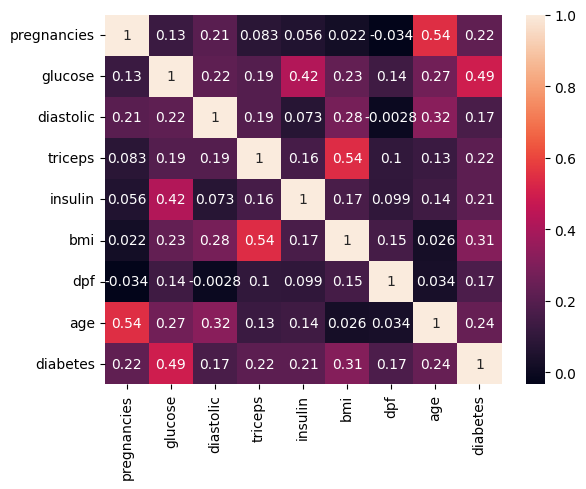

In [48]:
# Plot the correlation matrix
sns.heatmap(diabetes_df.corr(), annot=True)

Correlation analysis describes linear relationships among features and the target. Strong feature-to-feature correlations may indicate redundancy, while weak individual correlations can still help a nonlinear model.

Remember that correlation does not imply causation.

#### Split predictor features `X` and target `y`

Remove the `diabetes` column to create the predictor matrix `X_diabetes`.

In [49]:
X_diabetes = diabetes_df.drop(columns="diabetes")
X_diabetes.head()

,pregnancies,glucose,diastolic,triceps,insulin,bmi,dpf,age
0,6,148.0,72.0,35.00000,155.548223,33.6,0.627,50
1,1,85.0,66.0,29.00000,155.548223,26.6,0.351,31
2,8,183.0,64.0,29.15342,155.548223,23.3,0.672,32
3,1,89.0,66.0,23.00000,94.000000,28.1,0.167,21
4,0,137.0,40.0,35.00000,168.000000,43.1,2.288,33


Select the `diabetes` column as the target vector `y_diabetes`.

In [50]:
y_diabetes = diabetes_df["diabetes"]
y_diabetes.head()

0    1
1    0
2    1
3    0
4    1
Name: diabetes, dtype: int64

#### Split the data into training and test sets

Use 70% of the data for training and reserve 30% for the final test. Stratification preserves the target class ratio in both sets.

In [51]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_diabetes,
    y_diabetes,
    test_size=0.3,
    stratify=y_diabetes,
)

## 3. Build and train the neural network

A compact network with ReLU hidden layers and a sigmoid output predicts the probability of diabetes.

TensorFlow and scikit-learn are installed in the setup cell above. TensorFlow provides the Keras API used to build the neural network.

#### Define a simple neural network

Import `Sequential` to stack layers and `Dense` to create fully connected layers.

In [52]:
# Import the modules used to build the model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

The network has two hidden ReLU layers with 12 and 8 units. A single sigmoid output returns the estimated probability of diabetes.

In [54]:
# To define the input shape of the model, we need to know the number of features in the training data. The shape of X_train is (number of samples, number of features). By accessing X_train.shape[1], we get the number of features, which will be used as the input dimension for the first layer of the neural network.
X_train.shape[1] 

8

In [ ]:
model = Sequential([
    tf.keras.Input(shape=(X_train.shape[1],)),
    Dense(12, activation="relu"),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid"),
])

# Change the output layer from one unit to two:
# Dense(2, activation="softmax")

#### Compile the neural network

Compile with Adam, binary cross-entropy, and accuracy. Binary cross-entropy matches the two possible target classes.

In [56]:
# Compile with Adam, binary cross-entropy, and accuracy
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

#### Inspect the neural-network summary

`model.summary()` displays each layer, its output shape, and its trainable parameters.

In [57]:
# Display the model summary
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 12)             │           108 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 221 (884.00 B)

 Trainable params: 221 (884.00 B)

 Non-trainable params: 0 (0.00 B)

In [58]:
# Display the model output shape
model.output_shape

(None, 1)

#### Train the neural network

`model.fit()` learns from the training examples. An epoch is one pass through the training set; `batch_size` controls how many examples are processed before each weight update.

#### Train with early stopping to reduce overfitting

In [59]:
log_dir = Path("logs/fit") / datetime.now().strftime("%Y%m%d-%H%M%S")
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=20, restore_best_weights=True
    ),
    tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1),
]

history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=32,
    callbacks=callbacks,
    verbose=1,
)
print(f"TensorBoard logs written to: {log_dir}")

Epoch 1/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3669 - loss: 12.8460 - val_accuracy: 0.3889 - val_loss: 7.4581
Epoch 2/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3583 - loss: 8.3318 - val_accuracy: 0.4259 - val_loss: 4.5445
Epoch 3/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4088 - loss: 5.5963 - val_accuracy: 0.4815 - val_loss: 2.9081
Epoch 4/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4517 - loss: 3.2738 - val_accuracy: 0.5278 - val_loss: 1.9787
Epoch 5/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4600 - loss: 2.0000 - val_accuracy: 0.5185 - val_loss: 1.4599
Epoch 6/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4760 - loss: 1.7700 - val_accuracy: 0.5463 - val_loss: 1.1751
Epoch 7/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5596 - loss: 1.1923 - val_accuracy: 0.6111 - val_loss: 1.0282
Epoch 8/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5534 - loss: 1.2045 - val_accuracy: 0.6667 - 

In [ ]:
%load_ext tensorboard

In [ ]:
%tensorboard --logdir logs/fit # Make sure to run this command in the specific folder where the logs are stored. You can also specify a different log directory if you have set it up differently in the code above.

## 4. Evaluate the model

Evaluate loss and accuracy on both the training and test sets. Compare the results to check for potential overfitting.

In [60]:
# Evaluate on the training data
scores = model.evaluate(X_train, y_train, verbose=False)
print("Training accuracy: %.2f%%" % (scores[1] * 100))

# Evaluate on the test data
scores = model.evaluate(X_test, y_test, verbose=False)
print("Test accuracy: %.2f%%" % (scores[1] * 100))

Training accuracy: 66.29%
Test accuracy: 62.34%


## 5. Make a prediction

Select one example from the test set. `iloc[9]` returns its tenth row.

In [67]:
# Select a person from the test set for prediction
persona_de_prueba = X_test.iloc[10]
persona_de_prueba

pregnancies      9.000
glucose        145.000
diastolic       88.000
triceps         34.000
insulin        165.000
bmi             30.300
dpf              0.771
age             53.000
Name: 516, dtype: float64

Keras expects a two-dimensional input. Reshape the selected row into one sample with eight features before calling `predict()`.

In [68]:
# Predict with the trained model
prediccion = model.predict(persona_de_prueba.values.reshape(1,8))
prediccion

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


array([[0.40752158]], dtype=float32)

Classify the predicted probability using a 0.5 threshold, then compare that class with the known test label.

In [69]:
# Classify the model prediction
if prediccion >= 0.5:
    print('Neural-network prediction: diabetes')
else:
    print('Neural-network prediction: no diabetes')
    
# Display the true test label
if y_test.iloc[10] == 1:
    print('Test dataset label: diabetes')
else:
    print('Test dataset label: no diabetes')

Neural-network prediction: no diabetes
Test dataset label: diabetes


## 6. Save and reload the model

In [70]:
# Save the model to a file
model.save('modelo_diabetes.keras')

In [71]:
# Load the model from the file
from tensorflow.keras.models import load_model
modelo_cargado = load_model('modelo_diabetes.keras')

In [72]:
# Predict with the reloaded model
prediccion_modelo_cargado = modelo_cargado.predict(persona_de_prueba.values.reshape(1,8))

# Classify the reloaded-model prediction
if prediccion_modelo_cargado >= 0.5:
    print('Reloaded-model prediction: diabetes')
else:
    print('Reloaded-model prediction: no diabetes')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
Reloaded-model prediction: no diabetes


## Activity: Optimize the neural-network architecture

### Goal
Work in groups to improve the diabetes classifier through hyperparameter search.

### Instructions

1. Form a group of 2 or work individually.
2. Search for a new dataset
3. Buils a neural network and use `keras-tuner`, or `optuna` to search for the best hyperparameters.
4. Evaluate the best model and report the results.

---

Las enfermedades cardiovasculares (ECV) son la causa número 1 de muerte a nivel mundial, teniendo un estimado de 17,9 millones de vidas cada año, lo que representa el 31% de todas las muertes en todo el mundo. Cuatro de las muertes por 5 CVD se deben a ataques cardíacos y accidentes cerebrovasculares, y un tercio de estas muertes ocurren prematuramente en personas menores de 70 años. La insuficiencia cardíaca es un evento común causado por las ECV y este conjunto de datos contiene 11 características que se pueden utilizar para predecir una posible enfermedad cardíaca. Las personas con enfermedad cardiovascular o que tienen un alto riesgo cardiovascular (debido a la presencia de uno o más factores de riesgo como hipertensión, diabetes, hiperlipidemia o enfermedad ya establecida) necesitan detección y manejo tempranos en los que un modelo de aprendizaje automático puede ser de gran ayuda. 

In [1]:
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import tensorflow as tf


In [2]:
heart_df = pd.read_csv("cardio_train1.csv")
heart_df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


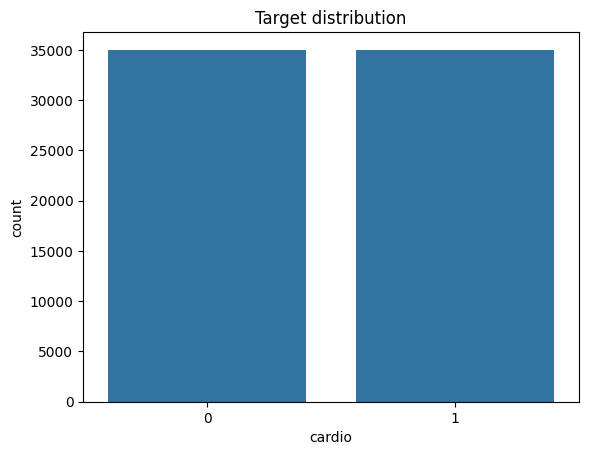

In [3]:
import seaborn as sns

sns.countplot(data=heart_df, x="cardio")
plt.title("Target distribution");

In [4]:
heart_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [5]:
heart_df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.419900,28851.302323,0.0,25006.75,50001.5,74889.25,99999.0
age,70000.0,19468.865814,2467.251667,10798.0,17664.00,19703.0,21327.00,23713.0
gender,70000.0,1.349571,0.476838,1.0,1.00,1.0,2.00,2.0
height,70000.0,164.359229,8.210126,55.0,159.00,165.0,170.00,250.0
weight,70000.0,74.205690,14.395757,10.0,65.00,72.0,82.00,200.0
ap_hi,70000.0,128.817286,154.011419,-150.0,120.00,120.0,140.00,16020.0
ap_lo,70000.0,96.630414,188.472530,-70.0,80.00,80.0,90.00,11000.0
cholesterol,70000.0,1.366871,0.680250,1.0,1.00,1.0,2.00,3.0
gluc,70000.0,1.226457,0.572270,1.0,1.00,1.0,1.00,3.0
smoke,70000.0,0.088129,0.283484,0.0,0.00,0.0,0.00,1.0


In [11]:
# Creamos una copia limpia del DataFrame original
heart_clean = heart_df.copy()

# 1. Transformamos la edad a años (para que sea legible humanamente)
heart_clean["age"] = heart_clean["age"] / 365.25

# 2. Aplicamos los filtros biológicos estrictos
heart_clean = heart_clean[
    # Filtros de presión arterial
    (heart_clean["ap_hi"] >= 70)
    & (heart_clean["ap_hi"] <= 240)
    & (heart_clean["ap_lo"] >= 40)
    & (heart_clean["ap_lo"] <= 140)
    & (heart_clean["ap_hi"] > heart_clean["ap_lo"])
    &
    # Filtros de antropometría (Peso y Altura)
    (heart_clean["weight"] >= 35)
    & (heart_clean["height"] >= 130)
    & (heart_clean["height"] <= 210)
]

print(
    f"Registros eliminados por inconsistencia médica: {len(heart_df) - len(heart_clean)}"
)

Registros eliminados por inconsistencia médica: 1441


In [12]:
heart_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 68559 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           68559 non-null  int64  
 1   age          68559 non-null  float64
 2   gender       68559 non-null  int64  
 3   height       68559 non-null  int64  
 4   weight       68559 non-null  float64
 5   ap_hi        68559 non-null  int64  
 6   ap_lo        68559 non-null  int64  
 7   cholesterol  68559 non-null  int64  
 8   gluc         68559 non-null  int64  
 9   smoke        68559 non-null  int64  
 10  alco         68559 non-null  int64  
 11  active       68559 non-null  int64  
 12  cardio       68559 non-null  int64  
dtypes: float64(2), int64(11)
memory usage: 7.3 MB


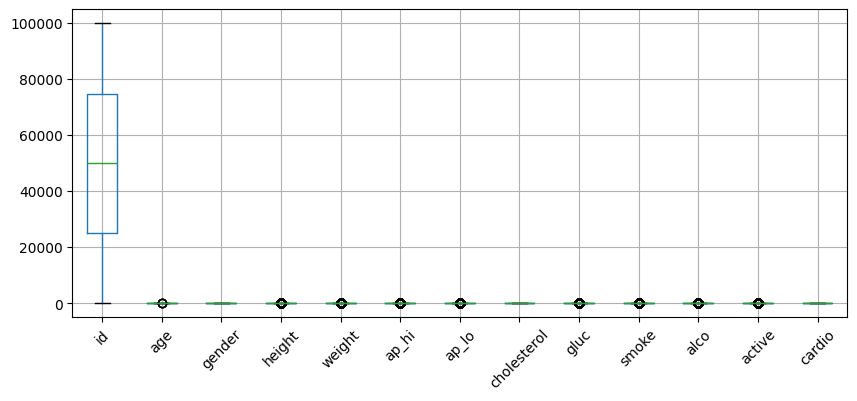

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
heart_clean.boxplot(ax=ax)
plt.xticks(rotation=45)
plt.show()

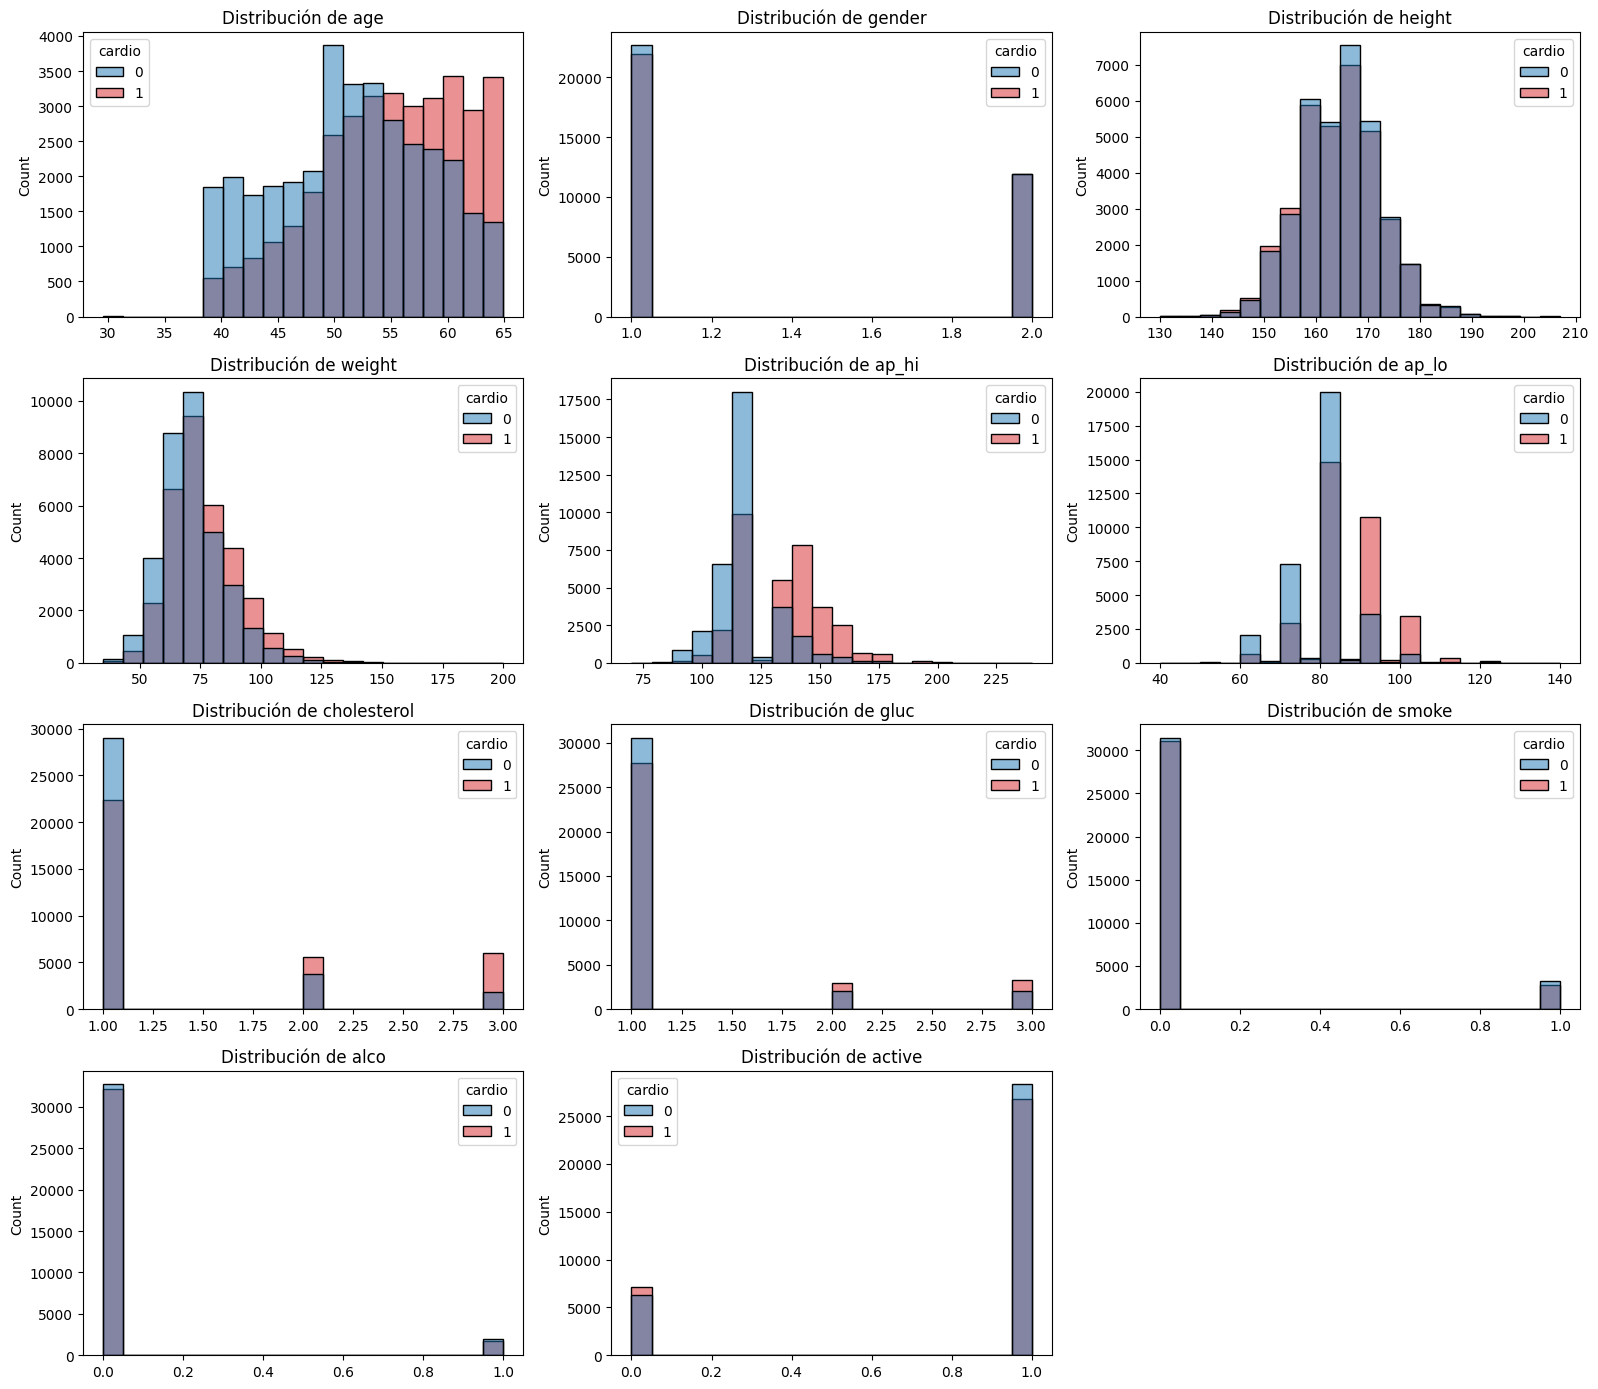

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Definimos las variables que queremos graficar (excluyendo 'id' y 'cardio')
variables = [col for col in heart_clean.columns if col not in ["id", "cardio"]]

# 2. Configuramos la cuadrícula de gráficos (ej. 4 filas x 3 columnas para las 11 variables)
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(16, 14))
axes = axes.flatten()  # Aplanamos la matriz de ejes para iterar fácilmente

# 3. Iteramos sobre cada columna para crear los histogramas diferenciados
for i, col in enumerate(variables):
    sns.histplot(
        data=heart_clean,
        x=col,
        hue="cardio",  # <-- Esto separa las barras por la categoría cardio
        multiple="layer",  # Superpone las capas para comparar distribuciones
        kde=False,  # Puedes cambiar a True si deseas ver la línea de densidad
        bins=20,
        ax=axes[i],
        palette={
            0: "#1f77b4",
            1: "#d62728",
        },  # Azul para No Cardio (0), Rojo para Cardio (1)
    )
    axes[i].set_title(f"Distribución de {col}")
    axes[i].set_xlabel("")  # Limpiamos la etiqueta del eje X para que no se repita con el título

# 4. Ocultamos los subplots sobrantes en la cuadrícula si los hay
for j in range(len(variables), len(axes)):
    fig.delaxes(axes[j])

# Ajustamos el espaciado
plt.tight_layout()
plt.show()


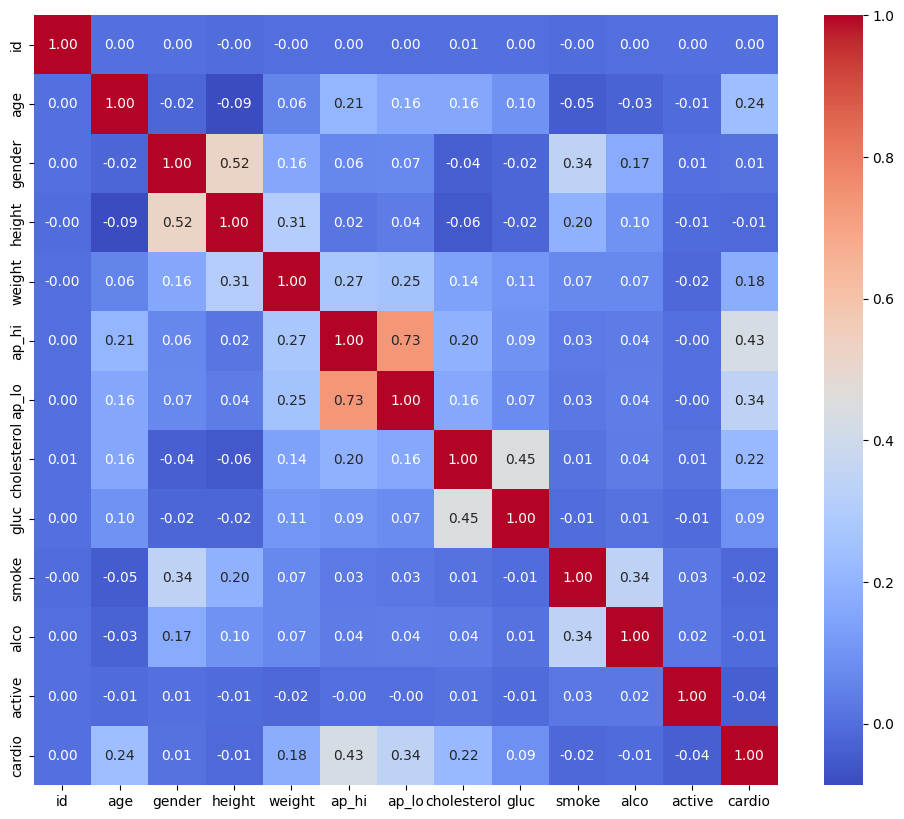

In [16]:
plt.figure(figsize=(12, 10))
sns.heatmap(heart_clean.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

C:\Users\DiegoR\AppData\Local\Temp\ipykernel_27476\1428784601.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)
C:\Users\DiegoR\AppData\Local\Temp\ipykernel_27476\1428784601.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)


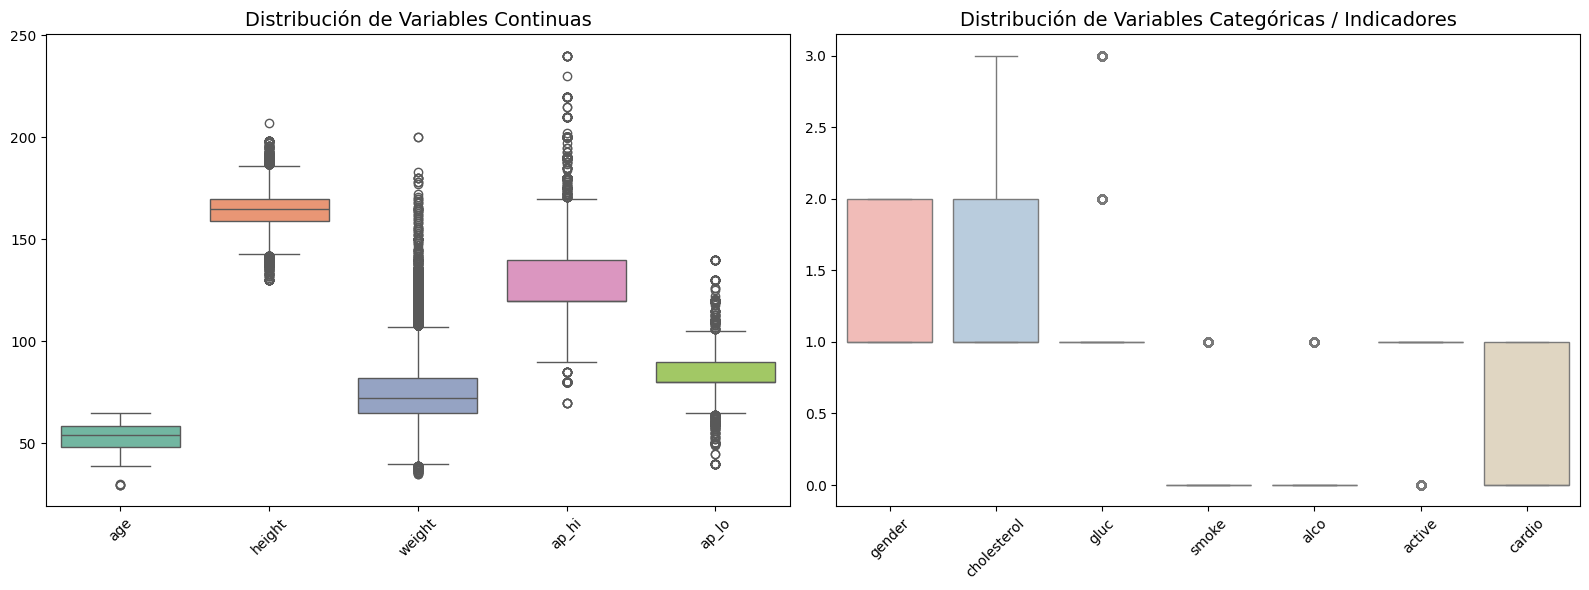

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Definimos las variables numéricas continuas (sin 'id') y las categóricas/binarias
# Nota: Si 'age' está en días, puedes pasarla a años haciendo: heart_clean['age_years'] = heart_clean['age'] / 365.25

variables_continuas = ['age', 'height', 'weight', 'ap_hi', 'ap_lo']
variables_binarias = ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']

# 2. Creamos una figura con dos subplots para separar las escalas
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Variables Continuas (Escala grande)
sns.boxplot(data=heart_clean[variables_continuas], ax=axes[0], palette="Set2")
axes[0].set_title("Distribución de Variables Continuas", fontsize=14)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)

# Subplot 2: Variables Categóricas/Binarias (Escala 0 a 3)
sns.boxplot(data=heart_clean[variables_binarias], ax=axes[1], palette="Pastel1")
axes[1].set_title("Distribución de Variables Categóricas / Indicadores", fontsize=14)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)

plt.tight_layout()
plt.show()


In [18]:
X_heart = heart_clean.drop(columns="cardio")
X_heart.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active
0,0,50.357290,2,168,62.0,110,80,1,1,0,0,1
1,1,55.381246,1,156,85.0,140,90,3,1,0,0,1
2,2,51.627652,1,165,64.0,130,70,3,1,0,0,0
3,3,48.249144,2,169,82.0,150,100,1,1,0,0,1
4,4,47.841205,1,156,56.0,100,60,1,1,0,0,0


In [19]:
y_heart = heart_clean["cardio"]
y_heart.head()

0    0
1    1
2    1
3    1
4    0
Name: cardio, dtype: int64

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_heart,
    y_heart,
    test_size=0.3,
    stratify=y_heart,
)

In [21]:
# Import the modules used to build the model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [22]:
# To define the input shape of the model, we need to know the number of features in the training data. The shape of X_train is (number of samples, number of features). By accessing X_train.shape[1], we get the number of features, which will be used as the input dimension for the first layer of the neural network.
X_train.shape[1] 

12

In [23]:
model = Sequential([
    tf.keras.Input(shape=(X_train.shape[1],)),
    Dense(12, activation="relu"),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid"),
])

In [24]:
# Compile with Adam, binary cross-entropy, and accuracy
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])


In [25]:
# Display the model summary
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12)             │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 269 (1.05 KB)

 Trainable params: 269 (1.05 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
# Display the model output shape
model.output_shape


(None, 1)

In [27]:
log_dir = Path("logs/fit") / datetime.now().strftime("%Y%m%d-%H%M%S")
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=20, restore_best_weights=True
    ),
    tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1),
]

history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=32,
    callbacks=callbacks,
    verbose=1,
)
print(f"TensorBoard logs written to: {log_dir}")

Epoch 1/200
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.5340 - loss: 28.9711 - val_accuracy: 0.6227 - val_loss: 1.1811
Epoch 2/200
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.5654 - loss: 3.3656 - val_accuracy: 0.5728 - val_loss: 1.5196
Epoch 3/200
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.5793 - loss: 3.3556 - val_accuracy: 0.5316 - val_loss: 5.8298
Epoch 4/200
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.5894 - loss: 3.1059 - val_accuracy: 0.5153 - val_loss: 6.0986
Epoch 5/200
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.5890 - loss: 3.2729 - val_accuracy: 0.6185 - val_loss: 1.5399
Epoch 6/200
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.5843 - loss: 3.3400 - val_accuracy: 0.5373 - val_loss: 4.9078
Epoch 7/200
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.5991 - loss: 2.4457 - val_accuracy: 0.6458 - val_loss: 1.1599
Epoch 8/200
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6080 - loss: 

In [28]:
%load_ext tensorboard

In [30]:
%tensorboard --logdir logs/fit # Make sure to run this command in the specific folder where the logs are stored. You can also specify a different log directory if you have set it up differently in the code above.


Reusing TensorBoard on port 6006 (pid 12280), started 0:00:12 ago. (Use '!kill 12280' to kill it.)

In [31]:
# Evaluate on the training data
scores = model.evaluate(X_train, y_train, verbose=False)
print("Training accuracy: %.2f%%" % (scores[1] * 100))

# Evaluate on the test data
scores = model.evaluate(X_test, y_test, verbose=False)
print("Test accuracy: %.2f%%" % (scores[1] * 100))

Training accuracy: 71.56%
Test accuracy: 71.10%


In [32]:
# Select a person from the test set for prediction
persona_de_prueba = X_test.iloc[10]
persona_de_prueba


id             62582.000000
age               53.700205
gender             1.000000
height           170.000000
weight            75.000000
ap_hi            120.000000
ap_lo             80.000000
cholesterol        1.000000
gluc               1.000000
smoke              0.000000
alco               0.000000
active             1.000000
Name: 43796, dtype: float64

In [33]:
# Predict with the trained model
prediccion = model.predict(persona_de_prueba.values.reshape(1,12))
prediccion

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


array([[0.25498483]], dtype=float32)

In [35]:
# Classify the model prediction
if prediccion >= 0.5:
    print('Neural-network prediction: ENFERMEDAD CARDIOVASCULAR')
else:
    print('Neural-network prediction: NO ENFERMEDAD CARDIOVASCULAR')
    
# Display the true test label
if y_test.iloc[10] == 1:
    print('Test dataset label: ENFERMEDAD CARDIOVASCULAR')
else:
    print('Test dataset label: NO ENFERMEDAD CARDIOVASCULAR')
	

Neural-network prediction: NO ENFERMEDAD CARDIOVASCULAR
Test dataset label: NO ENFERMEDAD CARDIOVASCULAR


In [36]:

# Save the model to a file
model.save('modelo_heart.keras')

In [37]:
# Load the model from the file
from tensorflow.keras.models import load_model
modelo_cargado = load_model('modelo_heart.keras')



In [39]:
# Predict with the reloaded model
prediccion_modelo_cargado = modelo_cargado.predict(persona_de_prueba.values.reshape(1,12))



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


In [40]:
# Classify the reloaded-model prediction
if prediccion_modelo_cargado >= 0.5:
    print('Reloaded-model prediction: ENFERMEDAD CARDIOVASCULAR')
else:
    print('Reloaded-model prediction: NO ENFERMEDAD CARDIOVASCULAR')

Reloaded-model prediction: NO ENFERMEDAD CARDIOVASCULAR


---

AJUSTE DE HIPERPARAMETROS

In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

# 1. Separamos las variables según el criterio de tus gráficos
variables_continuas = ["age", "height", "weight", "ap_hi", "ap_lo"]

# Identificamos el resto de columnas que NO queremos alterar (binarias y categorías numéricas)
variables_passthrough = [
    col for col in X_heart.columns if col not in variables_continuas
]

# 2. Hacemos el split estratificado original
X_train, X_test, y_train, y_test = train_test_split(
    X_heart, y_heart, test_size=0.3, stratify=y_heart, random_state=42
)

# 3. Creamos el transformador por columnas: aplica RobustScaler a continuas y deja pasar las demás
preprocessor = ColumnTransformer(
    transformers=[
        ("num_robust", RobustScaler(), variables_continuas),
        ("cat_keep", "passthrough", variables_passthrough),
    ]
)

# 4. Ajustamos en entrenamiento y transformamos ambos conjuntos
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

# Mostramos el cambio de dimensiones y una muestra para verificar
print("Forma final de X_train_scaled:", X_train_scaled.shape)
print("\nPrimer registro transformado (Primeros 5 elementos son los continuos escalados):")
print(X_train_scaled[0])


Forma final de X_train_scaled: (47991, 12)

Primer registro transformado (Primeros 5 elementos son los continuos escalados):
[-2.11298207e-01  2.72727273e-01  6.47058824e-01  0.00000000e+00
  0.00000000e+00  4.38020000e+04  1.00000000e+00  1.00000000e+00
  1.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]


In [ ]:
#%pip install keras-tuner -q

Note: you may need to restart the kernel to use updated packages.


In [44]:
import keras_tuner as kt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


def build_hypermodel_dynamic(hp):
    model = keras.Sequential()
    model.add(layers.Input(shape=(X_train_scaled.shape[1],)))

    # CONFIGURACIÓN DINÁMICA DE CAPAS (Busca automáticamente entre 1 y 3 capas ocultas)
    # KerasTuner decidirá cuántas capas son óptimas basándose en los datos
    num_layers = hp.Int("num_layers", min_value=1, max_value=3, default=2)

    for i in range(num_layers):
        model.add(
            layers.Dense(
                # Elige un número óptimo de neuronas de manera independiente para cada capa
                units=hp.Int(
                    f"units_layer_{i}", min_value=8, max_value=64, step=8
                ),
                activation="relu",
            )
        )

        # Agregamos Dropout opcional para evitar el sobreajuste si decide usar 3 capas
        if hp.Boolean(f"dropout_{i}"):
            model.add(layers.Dropout(rate=0.2))

    # Capa de salida fija para diagnóstico clínico binario (cardio: 0 o 1)
    model.add(layers.Dense(1, activation="sigmoid"))

    # Tasa de aprendizaje controlada
    lr = hp.Float("learning_rate", min_value=1e-4, max_value=1e-2, sampling="log")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )

    return model


print("¡HyperModel dinámico actualizado con soporte de 1 a 3 capas!")


¡HyperModel dinámico actualizado con soporte de 1 a 3 capas!


In [45]:
import os
import keras_tuner as kt
from tensorflow import keras

# 1. Definimos el "Supervisor" (EarlyStopping) con paciencia
# Si la pérdida de validación no mejora durante 15 épocas, detiene el entrenamiento
# e inmediatamente recupera los mejores pesos históricos del modelo.
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,          # Tolerancia de 15 épocas antes de tirar la toalla
    restore_best_weights=True
)

# 2. Inicializamos el motor de búsqueda de KerasTuner
# Nota: Cambiamos validation_split de .fit() por una validación fija directa usando tus datos estratificados.
tuner = kt.RandomSearch(
    hypermodel=build_hypermodel_dynamic,
    objective="val_loss",       # Nuestro objetivo clínico es MINIMIZAR el error de validación
    max_trials=8,               # Probará 8 combinaciones de arquitecturas diferentes
    executions_per_trial=1,     # Entrena 1 vez cada combinación para ahorrar tiempo
    directory="keras_tuner_logs", # Carpeta local donde guardará el progreso
    project_name="heart_disease_optimization",
    overwrite=True             # Si vuelves a correr la celda, reinicia la búsqueda desde cero
)

# 3. Imprimimos un resumen de los rangos de hiperparámetros que buscará
tuner.search_space_summary()

print("\n Lanzando búsqueda de hiperparámetros. Esto tomará unos momentos por cada intento...")

# 4. Lanzamos la búsqueda interactiva
tuner.search(
    X_train_scaled,
    y_train,
    epochs=100,                 # Ponemos un límite alto, pero EarlyStopping lo frenará antes si es necesario
    batch_size=32,
    validation_data=(X_test_scaled, y_test), # Evaluamos contra el conjunto de prueba aislado
    callbacks=[early_stopping],
    verbose=1
)


Trial 8 Complete [00h 02m 43s]
val_loss: 0.601019024848938

Best val_loss So Far: 0.5917071104049683
Total elapsed time: 00h 09m 20s


In [46]:
# 1. Recuperar los mejores hiperparámetros encontrados por KerasTuner
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

print("==================================================")
print("🏆 ARQUITECTURA GANADORA ENCONTRADA BY KERASTUNER 🏆")
print("==================================================")
print(f"-> Número óptimo de capas ocultas: {best_hps.get('num_layers')}")

for i in range(best_hps.get("num_layers")):
    print(f"   * Capa {i+1} - Neuronas: {best_hps.get(f'units_layer_{i}')}")
    print(f"   * Capa {i+1} - ¿Activó Dropout?: {best_hps.get(f'dropout_{i}')}")

print(
    f"-> Tasa de aprendizaje (Learning Rate) ideal: {best_hps.get('learning_rate'):.6f}"
)
print("==================================================\n")

# 2. Construir el modelo final con los mejores parámetros y entrenar de forma definitiva
print(" Re-entrenando el modelo óptimo con las mejores condiciones...")
best_model = tuner.hypermodel.build(best_hps)

# Entrenamos una última vez para asegurar capturar el punto exacto de convergencia
history_final = best_model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_test_scaled, y_test),
    callbacks=[early_stopping],
    verbose=0,  # Silencioso para no saturar la pantalla
)

# 3. Evaluación final del rendimiento del modelo
train_scores = best_model.evaluate(X_train_scaled, y_train, verbose=False)
test_scores = best_model.evaluate(X_test_scaled, y_test, verbose=False)

print("\n==================================================")
print("📊 RESULTADOS FINALES DE PRECISIÓN (ACCURACY) 📊")
print("==================================================")
print(f"Training accuracy (Exactitud Entrenamiento): {train_scores[1] * 100:.2f}%")
print(f"Test accuracy (Exactitud Prueba): {test_scores[1] * 100:.2f}%")
print("==================================================")


🏆 ARQUITECTURA GANADORA ENCONTRADA BY KERASTUNER 🏆
-> Número óptimo de capas ocultas: 1
   * Capa 1 - Neuronas: 56
   * Capa 1 - ¿Activó Dropout?: False
-> Tasa de aprendizaje (Learning Rate) ideal: 0.003419

 Re-entrenando el modelo óptimo con las mejores condiciones...

📊 RESULTADOS FINALES DE PRECISIÓN (ACCURACY) 📊
Training accuracy (Exactitud Entrenamiento): 72.58%
Test accuracy (Exactitud Prueba): 71.83%


The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 12280), started 1:19:25 ago. (Use '!kill 12280' to kill it.)


 Visualizando métricas médicas detalladas...
643/643 ━━━━━━━━━━━━━━━━━━━━ 0s 449us/step


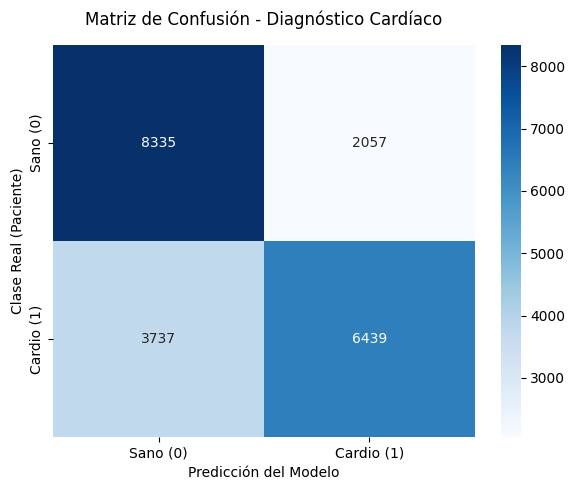


📋 REPORTE DE CLASIFICACIÓN CLÍNICA 📋
              precision    recall  f1-score   support

    Sano (0)       0.69      0.80      0.74     10392
  Cardio (1)       0.76      0.63      0.69     10176

    accuracy                           0.72     20568
   macro avg       0.72      0.72      0.72     20568
weighted avg       0.72      0.72      0.72     20568



In [47]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

# 1. Cargamos y activamos la extensión de TensorBoard dentro de Jupyter
%load_ext tensorboard
%tensorboard --logdir logs/fit

print("\n Visualizando métricas médicas detalladas...")

# 2. Generamos las predicciones probabilísticas del modelo final sobre los datos de prueba
y_pred_prob = best_model.predict(X_test_scaled)
# Convertimos las probabilidades en clases binarias (0 o 1) usando el umbral estándar de 0.5
y_pred = (y_pred_prob > 0.5).astype(int)

# 3. Calculamos la Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)

# 4. Graficamos la Matriz de Confusión de forma elegante
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Sano (0)", "Cardio (1)"],
    yticklabels=["Sano (0)", "Cardio (1)"],
)
plt.title("Matriz de Confusión - Diagnóstico Cardíaco", fontsize=12, pad=15)
plt.xlabel("Predicción del Modelo", fontsize=10)
plt.ylabel("Clase Real (Paciente)", fontsize=10)
plt.tight_layout()
plt.show()

# 5. Imprimimos el Reporte de Clasificación (Precision, Recall, F1-Score)
print("\n==================================================")
print("📋 REPORTE DE CLASIFICACIÓN CLÍNICA 📋")
print("==================================================")
print(classification_report(y_test, y_pred, target_names=["Sano (0)", "Cardio (1)"]))
print("==================================================")


In [50]:
import numpy as np
import pandas as pd
from tensorflow.keras.models import load_model

print("==================================================")
print("🧪 PRUEBA INDIVIDUAL CON EL MODELO OPTIMIZADO 🧪")
print("==================================================")

# 1. Extraer la persona de prueba original (sin escalar) para ver sus datos clínicos
persona_de_prueba = X_test.iloc[10]
print("Datos originales del paciente seleccionado (Índice 10):")
print(persona_de_prueba)
print("-" * 50)

# 2. ¡EL PASO CLAVE!: Escalar los datos del paciente antes de predecir
# Convertimos la serie en un DataFrame de una sola fila para que el preprocessor la acepte
persona_df = pd.DataFrame([persona_de_prueba])
persona_escalada = preprocessor.transform(persona_df)

# 3. Realizar la predicción con el mejor modelo encontrado (best_model)
prediccion = best_model.predict(persona_escalada, verbose=0)

# Clasificar la predicción probabilística del modelo actual
if prediccion >= 0.5:
    print(
        f"Predicción de la Red Neuronal: ENFERMEDAD CARDIOVASCULAR (Probabilidad: {prediccion[0][0]*100:.2f}%)"
    )
else:
    print(
        f"Predicción de la Red Neuronal: NO ENFERMEDAD CARDIOVASCULAR (Probabilidad: {prediccion[0][0]*100:.2f}%)"
    )

# 4. Mostrar la etiqueta real de control del dataset
etiqueta_real = y_test.iloc[10]
if etiqueta_real == 1:
    print("Etiqueta real del Dataset: ENFERMEDAD CARDIOVASCULAR")
else:
    print("Etiqueta real del Dataset: NO ENFERMEDAD CARDIOVASCULAR")
print("==================================================\n")

🧪 PRUEBA INDIVIDUAL CON EL MODELO OPTIMIZADO 🧪
Datos originales del paciente seleccionado (Índice 10):
id             25193.000000
age               50.036961
gender             1.000000
height           148.000000
weight            71.000000
ap_hi            120.000000
ap_lo             80.000000
cholesterol        1.000000
gluc               2.000000
smoke              0.000000
alco               0.000000
active             0.000000
Name: 17632, dtype: float64
--------------------------------------------------
Predicción de la Red Neuronal: NO ENFERMEDAD CARDIOVASCULAR (Probabilidad: 34.90%)
Etiqueta real del Dataset: ENFERMEDAD CARDIOVASCULAR



In [51]:
import numpy as np
import pandas as pd
from tensorflow.keras.models import load_model

print("==================================================")
print("🧪 PRUEBA INDIVIDUAL CON EL MODELO OPTIMIZADO 🧪")
print("==================================================")

# 1. Extraer la persona de prueba original (sin escalar) para ver sus datos clínicos
persona_de_prueba = X_test.iloc[11]
print("Datos originales del paciente seleccionado (Índice 11):")
print(persona_de_prueba)
print("-" * 50)

# 2. ¡EL PASO CLAVE!: Escalar los datos del paciente antes de predecir
# Convertimos la serie en un DataFrame de una sola fila para que el preprocessor la acepte
persona_df = pd.DataFrame([persona_de_prueba])
persona_escalada = preprocessor.transform(persona_df)

# 3. Realizar la predicción con el mejor modelo encontrado (best_model)
prediccion = best_model.predict(persona_escalada, verbose=0)

# Clasificar la predicción probabilística del modelo actual
if prediccion >= 0.5:
    print(
        f"Predicción de la Red Neuronal: ENFERMEDAD CARDIOVASCULAR (Probabilidad: {prediccion[0][0]*100:.2f}%)"
    )
else:
    print(
        f"Predicción de la Red Neuronal: NO ENFERMEDAD CARDIOVASCULAR (Probabilidad: {prediccion[0][0]*100:.2f}%)"
    )

# 4. Mostrar la etiqueta real de control del dataset
etiqueta_real = y_test.iloc[11]
if etiqueta_real == 1:
    print("Etiqueta real del Dataset: ENFERMEDAD CARDIOVASCULAR")
else:
    print("Etiqueta real del Dataset: NO ENFERMEDAD CARDIOVASCULAR")
print("==================================================\n")





🧪 PRUEBA INDIVIDUAL CON EL MODELO OPTIMIZADO 🧪
Datos originales del paciente seleccionado (Índice 11):
id             71841.000000
age               53.859001
gender             1.000000
height           156.000000
weight            76.000000
ap_hi            140.000000
ap_lo             80.000000
cholesterol        1.000000
gluc               1.000000
smoke              0.000000
alco               0.000000
active             1.000000
Name: 50338, dtype: float64
--------------------------------------------------
Predicción de la Red Neuronal: ENFERMEDAD CARDIOVASCULAR (Probabilidad: 64.97%)
Etiqueta real del Dataset: ENFERMEDAD CARDIOVASCULAR



In [ ]:
print("==================================================")
print("💾 GUARDADO Y VERIFICACIÓN DEL MODELO OPTIMIZADO 💾")
print("==================================================")

# 5. Guardar el mejor modelo optimizado en formato nativo Keras
best_model.save("modelo_heart_optimizado.keras")
print("-> ¡Modelo 'modelo_heart_optimizado.keras' guardado con éxito!")

# 6. Cargar el modelo desde el disco duro
modelo_cargado = load_model("modelo_heart_optimizado.keras")
print("-> ¡Modelo recargado correctamente desde el archivo!")

# 7. Predecir con el modelo recargado usando los mismos datos escalados
prediccion_cargado = modelo_cargado.predict(persona_escalada, verbose=0)

# Clasificar la predicción del modelo que guardamos
if prediccion_cargado >= 0.5:
    print("Predicción del Modelo Cargado: ENFERMEDAD CARDIOVASCULAR")
else:
    print("Predicción del Modelo Cargado: NO ENFERMEDAD CARDIOVASCULAR")
print("==================================================")

---

a. Which hyperparameter search method did you use?
- *Write your answer here...* Use la herramienta de random search con  keras tuner, los hyperparmetros usados fueron: numero de capas ocultas de 1 a 3; la cantidad de neuronas de 8 a 64 con steps de 8, con Regularización  dropout_X  condicional (True/False) con una tasa fija del 20% ; una tasa de aprendimiento de tipo min_value=1e-4 (0.0001) a **1e-2 (0.01) con sampling='log';  con un EarlyStopping de paciencia de 15 épocas y restore_best_weights=True para monitorizar la pérdida de validación (val_loss).

b. Which parameters did you search?
- *Write your answer here...* 
-> Número óptimo de capas ocultas: 1
   * Capa 1 - Neuronas: 56
   * Capa 1 - ¿Activó Dropout?: False - Innecesario debido a la simplicidad y estabilidad del modelo.
-> Tasa de aprendizaje (Learning Rate) ideal: 0.003419 -Ligeramente superior al valor por defecto, facilitando una convergencia rápida y segura
Training accuracy (Exactitud Entrenamiento): 72.58%
Test accuracy (Exactitud Prueba): 71.83%

c. How do the optimized network metrics compare with the baseline network?
- *Write your answer here...*
Mejora en las tasas de perdida, sin embargo en terminos de precicion se puede ver que estan casi proximos 
Linea base
Training accuracy: 71.56%
Test accuracy: 71.10%
Epoch 71/200
accuracy: 0.5203 - loss: 0.6883 - val_accuracy: 0.5326 - val_loss: 0.6837

Mejor modelo
Trial 8 Complete [00h 02m 43s]
val_loss: 0.601019024848938
Training accuracy (Exactitud Entrenamiento): 72.58%
Test accuracy (Exactitud Prueba): 71.83%

Adicionalmente, a pesar de que ambos modelos tienen casi semejantes resultados se observo que la prediccion ocupada para ambos casos el primero modelo acerto al valor de testeo mientras el seguno fallo, situacion esperada. Esto revela que la variable a justar no necesariamente deberia ser el accuracy, porbablemente usar Racall.



d. What else would you try to improve the metrics or reduce overfitting?
- *Write your answer here...*
Se podría probar un escalado híbrido: aplicar StandardScaler a las normales e interactuar con RobustScaler o transformaciones logarítmicas exclusivamente para las presiones arteriales.
Aplicar ingenieria de variables como el cálculo de la Presión de Pulso (ap_hi - ap_lo) o el Índice de Masa Corporal (IMC)
Usar otros modelos no necesariamente redes neuronales como  árboles de decisión como XGBoost, LightGBM o Random Forest
